In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import seaborn as sns

#%pip install geopandas
#%pip install contextily
#%pip install scikit-learn
import geopandas as gpd
import matplotlib.colors as colors
import contextily as ctx
import warnings
import plotly.express as px
import sklearn


plt.style.use('ggplot')
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
warnings.filterwarnings("ignore")


In [6]:
taxi = pd.read_csv("https://datasciencebocconi.github.io/Data/taxi_test.csv")
#taxi = pd.read_csv("/Users/andre/Desktop/BAI/3rd YEAR/DATA SCIENCE/test.csv")

In [7]:
taxi = taxi.drop_duplicates()

In [8]:
taxi.shape

(147546, 19)

In [9]:
taxi['pickup_wday'] = taxi['pickup_wday'].replace({
    1: 5,
    2: 6,
    3: 7,
    4: 1,
    5: 2,
    6: 3,
    7: 4
})

In [10]:
taxi['pickup_Borough'] = taxi['pickup_BoroCode']
taxi['dropoff_Borough'] = taxi['dropoff_BoroCode']

In [11]:
taxi['pickup_Borough'] = taxi['pickup_Borough'].replace({1: 'Manhattan',
                                                     2: 'Bronx', 
                                                     3: 'Brooklyn', 
                                                     4: 'Queens', 
                                                     5: 'Staten Island'})
taxi['dropoff_Borough'] = taxi['dropoff_Borough'].replace({1: 'Manhattan',
                                                       2: 'Bronx', 
                                                       3: 'Brooklyn', 
                                                       4: 'Queens', 
                                                       5: 'Staten Island'})

In [12]:
taxi['pickup_date'] = pd.to_datetime('2015-01-01') + pd.to_timedelta(taxi['pickup_doy'] - 2, unit='d')

In [13]:
taxi = taxi[['pickup_date'] + [col for col in taxi.columns if col != 'pickup_date']]

In [14]:
max_passenger_count = taxi['passenger_count'].max()
if max_passenger_count <= 6:
    print("The maximum value in passenger_count is no greater than 6.")
else:
    print("The maximum value in passenger_count is greater than 6.")

The maximum value in passenger_count is no greater than 6.


In [16]:
taxi_zones = gpd.read_file('/Users/Elizabeth/Desktop/Data Science/nyc_taxi_zones.shp')

In [17]:
# Convert the DataFrame to a GeoDataFrame - PICKUP
gdf_pickup = gpd.GeoDataFrame(taxi, geometry=gpd.points_from_xy(taxi.pickup_longitude, taxi.pickup_latitude))
gdf_pickup.crs = taxi_zones.crs

# Convert the DataFrame to a GeoDataFrame - DROPOFF
gdf_dropoff = gpd.GeoDataFrame(taxi, geometry=gpd.points_from_xy(taxi.dropoff_longitude, taxi.dropoff_latitude))
gdf_dropoff.crs = taxi_zones.crs

# Spatial join - PICKUP
pickup_zones = gpd.sjoin(gdf_pickup, taxi_zones, how='left', op='intersects')
pickup_zones.rename(columns={'zone': 'pickup_zone'}, inplace=True)

# Spatial join - DROPOFF
dropoff_zones = gpd.sjoin(gdf_dropoff, taxi_zones, how='left', op='intersects')
dropoff_zones.rename(columns={'zone': 'dropoff_zone'}, inplace=True)

# Combine the results by taking the 'pickup_zone' from pickup_zones and 'dropoff_zone' from dropoff_zones
# We assume each row corresponds to a unique ride and maintain the original index
taxi['pickup_zone'] = pickup_zones['pickup_zone']
taxi['dropoff_zone'] = dropoff_zones['dropoff_zone']

In [18]:
def manhattan_distance(lon1, lat1, lon2, lat2):
    """
    Calculate the Manhattan distance between two points in New York City
    """
    # Average latitude for New York City (for approximate mile conversion)
    avg_lat = 40.730610
    # Convert degrees latitude to miles
    lat_to_miles = 69.0
    # Convert degrees longitude to miles at New York City's average latitude
    lon_to_miles = np.cos(np.radians(avg_lat)) * 69.0

    # Calculate differences
    delta_lat_miles = np.abs(lat2 - lat1) * lat_to_miles
    delta_lon_miles = np.abs(lon2 - lon1) * lon_to_miles

    # Sum the absolute differences
    manhattan_miles = delta_lat_miles + delta_lon_miles
    
    return manhattan_miles

# Apply the function to DataFrame
taxi['manhattan_distance'] = manhattan_distance(taxi['pickup_longitude'], taxi['pickup_latitude'], 
                                                       taxi['dropoff_longitude'], taxi['dropoff_latitude'])

trip_distance_idx = taxi.columns.get_loc('trip_distance') + 1
taxi.insert(trip_distance_idx, 'manhattan_distance', taxi.pop('manhattan_distance'))

In [19]:
taxi.insert(taxi.columns.get_loc("manhattan_distance") + 1, "distance_diff", abs(taxi["trip_distance"] - taxi["manhattan_distance"]))

In [20]:
JFK_pickup_longitude = taxi[taxi['pickup_zone'] == 'JFK Airport']['pickup_longitude'].mean()
JFK_pickup_latitude = taxi[taxi['pickup_zone'] == 'JFK Airport']['pickup_latitude'].mean()
JFK_dropoff_longitude = taxi[taxi['dropoff_zone'] == 'JFK Airport']['dropoff_longitude'].mean()
JFK_dropoff_latitude = taxi[taxi['dropoff_zone'] == 'JFK Airport']['dropoff_latitude'].mean()

JFK_pickup_longitude, JFK_pickup_latitude, JFK_dropoff_longitude, JFK_dropoff_latitude

(-73.78426920503337, 40.645449909726835, -73.7860452087276, 40.645710507452776)

In [21]:
mask = (taxi['fare_amount'] == 52) & \
       (taxi['pickup_Borough'] == 'Manhattan') & \
       (taxi['dropoff_Borough'] == 'Manhattan')  

taxi[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone
2442,2015-05-16,22,5,20,137,6,22,1,MN03,1,MN03,-73.942879,40.808456,-73.942863,40.808479,2,2,0.00,0.002377,0.002377,52.0,MN03-MN03,Manhattan,Manhattan,Central Harlem North,Central Harlem North
2573,2015-05-30,7,5,22,151,6,6,1,MN31,1,MN31,-73.962158,40.762974,-73.962158,40.762974,1,1,14.10,0.000000,14.100000,52.0,MN31-MN31,Manhattan,Manhattan,Lenox Hill West,Lenox Hill West
3572,2015-05-01,13,5,18,122,5,8,1,MN17,1,MN17,-73.988258,40.758301,-73.988266,40.758305,1,2,0.00,0.000662,0.000662,52.0,MN17-MN17,Manhattan,Manhattan,Times Sq/Theatre District,Times Sq/Theatre District
3803,2015-05-04,11,5,18,125,1,64,1,MN13,1,MN13,-73.987411,40.741611,-73.987411,40.741611,2,1,0.00,0.000000,0.000000,52.0,MN13-MN13,Manhattan,Manhattan,Union Sq,Union Sq
5091,2015-05-16,9,5,20,137,6,491,1,MN21,1,MN13,-73.985550,40.741001,-73.992989,40.739059,2,1,0.91,0.522923,0.387077,52.0,MN21-MN13,Manhattan,Manhattan,Gramercy,Union Sq
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134646,2015-05-04,22,5,18,125,1,17,1,MN21,1,MN21,-73.979561,40.736343,-73.979561,40.736324,2,1,0.00,0.001316,0.001316,52.0,MN21-MN21,Manhattan,Manhattan,Gramercy,Gramercy
136304,2015-05-14,8,5,20,135,4,23,1,MN24,1,MN24,-74.005249,40.720959,-74.005234,40.720966,2,1,0.00,0.001324,0.001324,52.0,MN24-MN24,Manhattan,Manhattan,TriBeCa/Civic Center,TriBeCa/Civic Center
142514,2015-05-26,9,5,21,147,2,29,1,MN25,1,MN25,-74.015907,40.708447,-74.015602,40.708496,1,1,0.00,0.019379,0.019379,52.0,MN25-MN25,Manhattan,Manhattan,Battery Park City,Battery Park City
144166,2015-05-12,1,5,19,133,2,313,1,MN28,1,MN27,-73.986290,40.718067,-73.989716,40.715664,1,1,0.60,0.344940,0.255060,52.0,MN28-MN27,Manhattan,Manhattan,Two Bridges/Seward Park,Lower East Side


In [22]:
taxi.loc[mask, 'trip_distance'] = manhattan_distance(
    taxi[mask]['pickup_longitude'], 
    taxi[mask]['pickup_latitude'], 
    JFK_dropoff_longitude, 
    JFK_dropoff_latitude
)

In [23]:
taxi.loc[mask, 'dropoff_longitude'] = JFK_dropoff_longitude
taxi.loc[mask, 'dropoff_latitude'] = JFK_dropoff_latitude
taxi.loc[mask, 'dropoff_zone'] = 'JFK Airport'
taxi.loc[mask, 'dropoff_NTACode'] = 'QN98'
taxi.loc[mask, 'dropoff_BoroCode'] = 4
taxi.loc[mask, 'pair'] = taxi.loc[mask, 'pickup_NTACode'] + "-" + 'QN98'

In [24]:
taxi.loc[mask, 'manhattan_distance'] = taxi.loc[mask, 'trip_distance']
taxi.loc[mask, 'distance_diff'] = 0


In [25]:
mask = (((taxi['pickup_zone'] == 'JFK Airport') & (taxi['dropoff_Borough'] == 'Manhattan')) | 
        ((taxi['pickup_Borough'] == 'Manhattan') & (taxi['dropoff_zone'] == 'JFK Airport'))) & \
        (taxi['fare_amount'] != 52)

taxi[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone
4018,2015-05-19,4,5,20,140,2,2142,1,MN17,4,QN98,-73.982613,40.757118,-73.789864,40.646919,2,1,18.12,17.682041,0.437959,60.00,MN17-QN98,Manhattan,Queens,Times Sq/Theatre District,JFK Airport
33098,2015-05-02,13,5,18,123,6,4341,4,QN98,1,MN19,-73.782043,40.644680,-73.969551,40.756710,2,1,21.18,17.534325,3.645675,68.50,QN98-MN19,Queens,Manhattan,JFK Airport,Sutton Place/Turtle Bay North
36851,2015-05-05,12,5,18,126,2,2313,1,MN20,4,QN98,-73.977737,40.746307,-73.790085,40.646877,1,1,22.10,16.672509,5.427491,61.00,MN20-QN98,Manhattan,Queens,Murray Hill,JFK Airport
41047,2015-05-02,20,5,18,123,6,2001,4,QN98,1,MN31,-73.781929,40.644650,-73.951752,40.759499,2,5,17.14,16.804144,0.335856,48.00,QN98-MN31,Queens,Manhattan,JFK Airport,Roosevelt Island
69806,2015-05-19,18,5,20,140,2,6422,1,MN25,4,QN98,-74.009117,40.709751,-73.783379,40.643730,2,1,0.00,16.358687,16.358687,88.00,MN25-QN98,Manhattan,Queens,Financial District North,JFK Airport
70454,2015-05-11,8,5,19,132,1,4781,1,MN13,4,QN98,-74.001732,40.756367,-73.784836,40.643215,2,2,25.80,19.148350,6.651650,81.00,MN13-QN98,Manhattan,Queens,West Chelsea/Hudson Yards,JFK Airport
76667,2015-05-31,19,5,22,152,7,3988,4,QN98,1,MN40,-73.789566,40.647022,-73.956978,40.778236,1,1,22.90,17.807274,5.092726,69.00,QN98-MN40,Queens,Manhattan,JFK Airport,Upper East Side North
83909,2015-05-30,22,5,22,151,6,3206,4,QN98,1,MN31,-73.781769,40.644711,-73.964348,40.762547,1,2,27.60,17.677235,9.922765,76.50,QN98-MN31,Queens,Manhattan,JFK Airport,Lenox Hill West
86985,2015-05-25,17,5,21,146,1,5314,1,MN13,4,QN98,-73.995018,40.740040,-73.782555,40.648800,2,1,17.97,17.404675,0.565325,66.50,MN13-QN98,Manhattan,Queens,Flatiron,JFK Airport
96542,2015-05-06,22,5,19,127,3,3237,4,QN98,1,MN15,-73.781830,40.644878,-73.995903,40.764069,2,1,0.63,19.417417,18.787417,5.50,QN98-MN15,Queens,Manhattan,JFK Airport,Clinton West


In [26]:
taxi.loc[mask, 'fare_amount'] = 52 

In [27]:
mask = (((taxi['pickup_zone'] == 'JFK Airport') & (taxi['dropoff_Borough'] == 'Manhattan')) | 
        ((taxi['pickup_Borough'] == 'Manhattan') & (taxi['dropoff_zone'] == 'JFK Airport'))) & \
        (taxi['trip_distance'] < 13) 
taxi[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone
16802,2015-05-20,9,5,21,141,3,6960,1,MN17,4,QN98,-73.979149,40.766674,-73.790482,40.646786,1,2,2.10,18.137182,16.037182,52.0,MN17-QN98,Manhattan,Queens,Midtown North,JFK Airport
25132,2015-05-08,21,5,19,129,5,3834,4,QN98,1,MN14,-73.790512,40.643993,-73.981155,40.776756,1,1,0.00,19.128850,19.128850,52.0,QN98-MN14,Queens,Manhattan,JFK Airport,Lincoln Square East
69806,2015-05-19,18,5,20,140,2,6422,1,MN25,4,QN98,-74.009117,40.709751,-73.783379,40.643730,2,1,0.00,16.358687,16.358687,52.0,MN25-QN98,Manhattan,Queens,Financial District North,JFK Airport
96542,2015-05-06,22,5,19,127,3,3237,4,QN98,1,MN15,-73.781830,40.644878,-73.995903,40.764069,2,1,0.63,19.417417,18.787417,52.0,QN98-MN15,Queens,Manhattan,JFK Airport,Clinton West
137781,2015-05-21,8,5,21,142,4,1990,1,MN40,4,QN98,-73.959549,40.777115,-73.782898,40.643967,1,4,0.00,18.423816,18.423816,52.0,MN40-QN98,Manhattan,Queens,Upper East Side North,JFK Airport
146060,2015-05-14,13,5,20,135,4,3178,1,MN13,4,QN98,-73.999664,40.743553,-73.782936,40.648617,2,1,0.00,17.882726,17.882726,52.0,MN13-QN98,Manhattan,Queens,Flatiron,JFK Airport


In [28]:
taxi.loc[mask, 'trip_distance'] = taxi.loc[mask, 'manhattan_distance']
taxi.loc[mask, 'distance_diff'] = 0

In [29]:
mask = (((taxi['pickup_zone'] == 'JFK Airport') & (taxi['dropoff_Borough'] == 'Manhattan')) | 
        ((taxi['pickup_Borough'] == 'Manhattan') & (taxi['dropoff_zone'] == 'JFK Airport'))) 

In [30]:
duration_mask = taxi[mask & ((taxi['length_time'] > 7200) | (taxi['length_time'] < 1500))].index

average_duration = taxi.loc[mask & (taxi['length_time'] <= 7200) & (taxi['length_time'] >= 1500), 'length_time'].mean().round(0)
taxi.loc[duration_mask, 'length_time'] = average_duration


In [31]:
mask = ((taxi['pickup_zone'] == 'LaGuardia Airport') | (taxi['dropoff_zone'] == 'LaGuardia Airport')) & ((taxi['fare_amount'] < 5) | (taxi['trip_distance'] <= 0.4) | (taxi['length_time'] <= 180))

In [32]:
taxi.loc[mask, 'trip_distance'] = taxi.loc[mask, 'manhattan_distance']
taxi.loc[mask, 'distance_diff'] = 0
taxi.loc[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone
2217,2015-05-18,5,5,20,139,1,65,4,QN98,4,QN98,-73.861740,40.768551,-73.861824,40.768482,1,2,0.009126,0.009126,0.0,38.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
30119,2015-05-28,8,5,22,149,4,15,4,QN98,4,QN98,-73.865303,40.770367,-73.865356,40.770340,2,2,0.004635,0.004635,0.0,32.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
37597,2015-05-05,19,5,18,126,2,1757,1,MN17,4,QN98,-73.975647,40.762569,-73.864861,40.770390,2,6,6.332304,6.332304,0.0,17.0,MN17-QN98,Manhattan,Queens,Midtown Center,LaGuardia Airport
50259,2015-05-11,12,5,19,132,1,5,4,QN98,4,QN98,-73.865509,40.770828,-73.865509,40.770828,1,1,0.000000,0.000000,0.0,2.5,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
50819,2015-05-26,22,5,21,147,2,17,4,QN98,4,QN98,-73.879242,40.770634,-73.880653,40.769855,2,1,0.127496,0.127496,0.0,35.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
51667,2015-05-10,19,5,19,131,7,40,4,QN98,4,QN98,-73.864021,40.769897,-73.863861,40.769894,2,2,0.008641,0.008641,0.0,200.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
87148,2015-05-10,18,5,19,131,7,1,4,QN98,4,QN98,-73.865555,40.770962,-73.865555,40.770958,1,1,0.000263,0.000263,0.0,31.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
103107,2015-05-20,5,5,21,141,3,156,4,QN98,4,QN98,-73.870941,40.773682,-73.885147,40.772053,1,3,0.855181,0.855181,0.0,5.5,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport
127164,2015-05-26,0,5,21,147,2,0,4,QN98,1,MN04,-73.871201,40.773891,-73.952881,40.824696,2,5,7.776322,7.776322,0.0,27.0,QN98-MN04,Queens,Manhattan,LaGuardia Airport,Hamilton Heights
132607,2015-05-29,4,5,22,150,5,72,4,QN98,4,QN98,-73.872704,40.774277,-73.872711,40.774269,1,1,0.000925,0.000925,0.0,35.0,QN98-QN98,Queens,Queens,LaGuardia Airport,LaGuardia Airport


In [33]:
TRIP_DISTANCE_THRESHOLD = 1  # Consider "near zero" distances below this
DISTANCE_DIFF_THRESHOLD = 0.5 # Impute if the difference exceeds this

mask = (taxi['trip_distance'] <= TRIP_DISTANCE_THRESHOLD) & \
       (abs(taxi['trip_distance'] - taxi['manhattan_distance']) > DISTANCE_DIFF_THRESHOLD) & \
       (taxi['manhattan_distance'] > taxi['trip_distance'])

taxi[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone
1004,2015-05-07,18,5,19,128,4,815,1,MN99,1,MN15,-73.968040,40.771202,-73.994301,40.769840,1,2,0.00,1.467050,1.467050,11.0,MN99-MN15,Manhattan,Manhattan,Central Park,Clinton West
2779,2015-05-06,20,5,19,127,3,392,1,MN20,1,MN22,-73.979050,40.740520,-73.988625,40.727287,2,1,0.00,1.413734,1.413734,5.5,MN20-MN22,Manhattan,Manhattan,Kips Bay,East Village
2976,2015-05-12,9,5,19,133,2,358,1,MN99,1,MN09,-73.979256,40.767086,-73.968224,40.801620,2,6,0.84,2.959715,2.119715,6.0,MN99-MN09,Manhattan,Manhattan,Central Park,Bloomingdale
3956,2015-05-07,0,5,19,128,4,734,1,MN17,1,MN15,-73.988533,40.748459,-73.987099,40.765972,1,1,0.00,1.283413,1.283413,8.5,MN17-MN15,Manhattan,Manhattan,Midtown South,Clinton East
4850,2015-05-17,21,5,20,138,7,300,1,MN25,1,MN15,-74.015251,40.714138,-73.989212,40.759106,2,1,0.80,4.464281,3.664281,5.5,MN25-MN15,Manhattan,Manhattan,Battery Park City,Clinton East
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141059,2015-05-31,22,5,22,152,7,638,1,MN17,1,MN13,-73.979622,40.763256,-73.992371,40.742752,2,3,0.00,2.081371,2.081371,7.5,MN17-MN13,Manhattan,Manhattan,Midtown North,Union Sq
141737,2015-05-19,1,5,20,140,2,242,1,MN25,1,MN23,-74.013527,40.715176,-74.003143,40.739014,2,3,0.87,2.187755,1.317755,5.0,MN25-MN23,Manhattan,Manhattan,Battery Park City,West Village
143562,2015-05-16,20,5,20,137,6,178,1,MN24,1,MN24,-74.009132,40.716949,-74.009163,40.724670,2,5,0.00,0.534341,0.534341,3.5,MN24-MN24,Manhattan,Manhattan,TriBeCa/Civic Center,Hudson Sq
144291,2015-05-03,16,5,18,124,7,888,1,MN99,1,MN17,-73.966164,40.778118,-73.973846,40.763321,2,1,0.79,1.422720,0.632720,10.0,MN99-MN17,Manhattan,Manhattan,Central Park,Midtown North


In [34]:
taxi.loc[mask, 'trip_distance'] = taxi.loc[mask, 'manhattan_distance']
taxi.loc[mask, 'distance_diff'] = 0

In [35]:
NULL_DISTANCE = 0  
DISTANCE_DIFF_THRESHOLD = 0.01 

mask = (taxi['trip_distance'] == NULL_DISTANCE) & \
       (abs(taxi['trip_distance'] - taxi['manhattan_distance']) >= DISTANCE_DIFF_THRESHOLD) & \
       (taxi['manhattan_distance'] > taxi['trip_distance'])


In [36]:
taxi.loc[mask, 'trip_distance'] = taxi.loc[mask, 'manhattan_distance']
taxi.loc[mask, 'distance_diff'] = 0

In [37]:
mask_zero_distance = (taxi['trip_distance'] == NULL_DISTANCE) & \
                     ((taxi['fare_amount'] > 2.5) | \
                      ((taxi['fare_amount'] > 3.5) & ((taxi['pickup_hour'] >= 20) | (taxi['pickup_hour'] < 6)))) 

taxi.loc[mask_zero_distance, 'trip_distance'] = taxi.loc[mask_zero_distance, 'manhattan_distance']
taxi.loc[mask_zero_distance, 'distance_diff'] = 0

In [38]:
top_2_indices = taxi['trip_distance'].nlargest(2).index  
taxi.loc[top_2_indices, 'trip_distance'] = taxi.loc[top_2_indices, 'manhattan_distance']
taxi.loc[top_2_indices, 'distance_diff'] = 0

In [39]:
def calculate_median_length_time_by_zone(df, pickup_zone_column = 'pickup_zone', dropoff_zone_column = 'dropoff_zone', outlier_threshold=None):
    """Calculates mean length_time for each pickup zone, excluding outliers."""

    if outlier_threshold is not None:
        df = df[df['length_time'] <= outlier_threshold]  # Filter outliers first
    return df.groupby([pickup_zone_column, dropoff_zone_column])['length_time'].median() 


# Constants
LENGTH_TIME_THRESHOLD = 2 * 60 * 60  

# Filtering abnormal length_time
mask = taxi['length_time'] > LENGTH_TIME_THRESHOLD

#  mean length_time per zone (excluding outliers)
median_length_time_per_zone = calculate_median_length_time_by_zone(
    taxi, outlier_threshold=LENGTH_TIME_THRESHOLD
) 

median_length_time_per_zone

pickup_zone     dropoff_zone             
Alphabet City   Alphabet City                 212.5
                Astoria                      1103.0
                Battery Park City             778.5
                Bedford                      1227.0
                Bloomingdale                 1473.0
                                              ...  
Yorkville West  Williamsburg (North Side)    1301.5
                Williamsburg (South Side)    1285.0
                World Trade Center           1115.0
                Yorkville East                226.0
                Yorkville West                181.5
Name: length_time, Length: 8087, dtype: float64

In [40]:
bins = [0, 1, 2, 3, 5, 10, 15, 20, 25, 30, 35, 45]
labels = ['[0-1)', '[1-2)', '[2-3)', '[3-5)', '[5-10)', '[10-15)', '[15-20)', '[20-25)', '[25-30)', '[30-35)', '[35, 45)']
taxi['distance_bin'] = pd.cut(taxi['trip_distance'], bins=bins, labels=labels, include_lowest=True)

# Median Length Time by Distance Bin
median_length_time_per_distance_bin = taxi.groupby('distance_bin')['length_time'].median()
median_length_time_per_distance_bin

distance_bin
[0-1)        307.0
[1-2)        578.0
[2-3)        847.0
[3-5)       1116.0
[5-10)      1484.0
[10-15)     2081.0
[15-20)     2741.0
[20-25)     2974.5
[25-30)     3046.0
[30-35)     4685.0
[35, 45)    7760.0
Name: length_time, dtype: float64

In [41]:
# Check for NaN values
print(median_length_time_per_distance_bin.isnull().sum())  

# Examine bin counts (optional)
print(taxi['distance_bin'].value_counts())

0
distance_bin
[1-2)       48078
[0-1)       32600
[2-3)       24272
[3-5)       19327
[5-10)      14452
[10-15)      4708
[15-20)      3396
[20-25)       642
[25-30)        61
[30-35)         7
[35, 45)        3
Name: count, dtype: int64


In [42]:
def impute_with_median_length_time(row, median_length_time_per_zone, median_length_time_per_distance_bin):
    zone_pair = (row['pickup_zone'], row['dropoff_zone'])
    if zone_pair in median_length_time_per_zone.index:
        return median_length_time_per_zone.loc[zone_pair]
    else:
        distance_bin = pd.cut([row['trip_distance']], bins=bins, labels=labels, include_lowest=True)[0]
        return median_length_time_per_distance_bin.get(distance_bin, np.nan)

In [43]:
taxi.loc[mask, 'length_time'] = taxi[mask].apply(
    impute_with_median_length_time,
    median_length_time_per_zone=median_length_time_per_zone,
    median_length_time_per_distance_bin=median_length_time_per_distance_bin,
    axis=1
)


In [44]:
taxi.loc[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone,distance_bin
2500,2015-05-25,14,5,21,146,1,790.5,1,MN13,1,MN14,-73.995224,40.739700,-73.985809,40.770466,2,1,2.92,2.615089,0.304911,19.0,MN13-MN14,Manhattan,Manhattan,Flatiron,Lincoln Square East,[2-3)
9727,2015-05-13,17,5,20,134,3,304.0,1,MN20,1,MN21,-73.980225,40.745602,-73.983795,40.740574,2,1,0.40,0.533611,0.133611,3.5,MN20-MN21,Manhattan,Manhattan,Murray Hill,Gramercy,[0-1)
10239,2015-05-16,19,5,20,137,6,1105.5,4,QN98,1,MN32,-73.863564,40.769547,-73.949272,40.775944,2,2,8.65,4.922876,3.727124,27.0,QN98-MN32,Queens,Manhattan,LaGuardia Airport,Yorkville East,[5-10)
10313,2015-05-03,5,5,18,124,7,557.0,1,MN17,1,MN20,-73.991844,40.750149,-73.974861,40.742153,2,2,1.22,1.439692,0.219692,7.0,MN17-MN20,Manhattan,Manhattan,Penn Station/Madison Sq West,Kips Bay,[1-2)
10427,2015-05-09,8,5,19,130,6,314.5,1,MN19,1,MN31,-73.969177,40.757923,-73.958481,40.765484,2,1,1.01,1.080976,0.070976,6.5,MN19-MN31,Manhattan,Manhattan,Sutton Place/Turtle Bay North,Lenox Hill West,[1-2)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142072,2015-05-28,16,5,22,149,4,257.0,1,MN12,1,MN12,-73.979088,40.781994,-73.969734,40.793766,2,1,1.09,1.301354,0.211354,5.0,MN12-MN12,Manhattan,Manhattan,Upper West Side South,Upper West Side North,[1-2)
143435,2015-05-07,13,5,19,128,4,335.0,1,MN32,1,MN40,-73.945549,40.778633,-73.956078,40.785538,2,5,1.04,1.026927,0.013073,7.0,MN32-MN40,Manhattan,Manhattan,Yorkville East,Upper East Side North,[1-2)
144506,2015-05-09,23,5,19,130,6,499.0,1,MN17,1,MN15,-73.992035,40.749687,-73.987122,40.768536,2,2,1.71,1.557445,0.152555,8.0,MN17-MN15,Manhattan,Manhattan,Penn Station/Madison Sq West,Clinton East,[1-2)
145156,2015-05-18,11,5,20,139,1,820.0,1,MN23,3,BK73,-73.991135,40.733261,-73.965233,40.714176,2,2,3.69,2.671193,1.018807,17.0,MN23-BK73,Manhattan,Brooklyn,Greenwich Village North,Williamsburg (South Side),[3-5)


In [45]:
mask = (taxi['length_time'] == 0)
outlier_indices = taxi.loc[mask].index
taxi[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone,distance_bin
127164,2015-05-26,0,5,21,147,2,0.0,4,QN98,1,MN04,-73.871201,40.773891,-73.952881,40.824696,2,5,7.776322,7.776322,0.0,27.0,QN98-MN04,Queens,Manhattan,LaGuardia Airport,Hamilton Heights,[5-10)


In [46]:
def calculate_median_length_time_by_zone(df, pickup_zone_column = 'pickup_zone', dropoff_zone_column = 'dropoff_zone'):

    df = df[df['length_time'] != 0] 
    return df.groupby([pickup_zone_column, dropoff_zone_column])['length_time'].median() 

median_length_time_per_zone = calculate_median_length_time_by_zone(
    taxi
) 

def impute_zero_length_time(row, median_length_time_per_zone, median_length_time_per_distance_bin):
    zone_pair = (row['pickup_zone'], row['dropoff_zone'])
    if zone_pair in median_length_time_per_zone.index:
        return median_length_time_per_zone.loc[zone_pair]
    else:
        distance_bin = pd.cut([row['trip_distance']], bins=bins, labels=labels, include_lowest=True)[0]
        if distance_bin in median_length_time_per_distance_bin.index:
            return median_length_time_per_distance_bin.loc[distance_bin]
        else:
            return row['length_time']  

        

# Correct the invocation of the apply method
taxi.loc[mask, 'length_time'] = taxi[mask].apply(
    impute_zero_length_time,
    median_length_time_per_zone=median_length_time_per_zone,
    median_length_time_per_distance_bin=median_length_time_per_distance_bin,
    axis=1
)

taxi.loc[mask]

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone,distance_bin
127164,2015-05-26,0,5,21,147,2,1402.5,4,QN98,1,MN04,-73.871201,40.773891,-73.952881,40.824696,2,5,7.776322,7.776322,0.0,27.0,QN98-MN04,Queens,Manhattan,LaGuardia Airport,Hamilton Heights,[5-10)


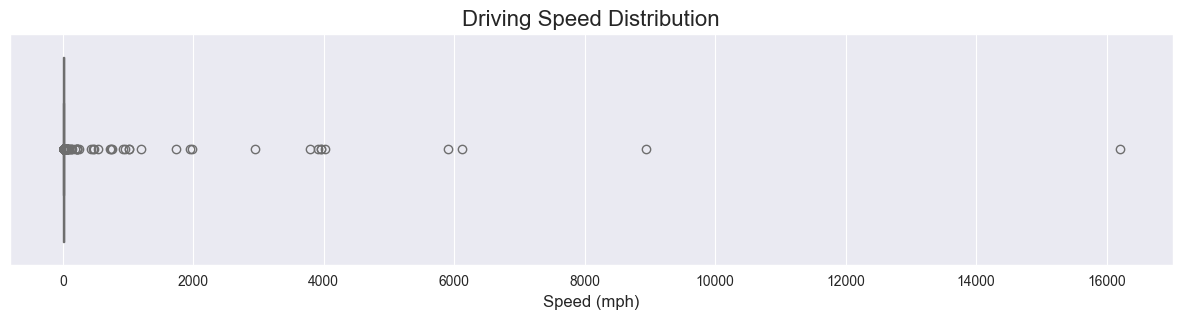

In [47]:
taxi['speed'] = (taxi['trip_distance'] / (taxi['length_time']/3600)).round(2)


plt.figure(figsize=(15, 3))
sns.set_style("darkgrid")
sns.boxplot(data = taxi, x = 'speed', color = 'violet')
plt.xlabel('Speed (mph)')
plt.title('Driving Speed Distribution', fontsize=16)
plt.show()

In [48]:
from sklearn.impute import KNNImputer

def categorize_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

taxi['time_of_day'] = taxi['pickup_hour'].apply(categorize_time_of_day)

taxi.loc[taxi['speed'] > 55, 'length_time'] = np.nan
numerical_cols = taxi.select_dtypes(include=['int', 'float']).columns

knn_imputer = KNNImputer(n_neighbors=5)  
taxi[numerical_cols] = knn_imputer.fit_transform(taxi[numerical_cols])
taxi['speed'] = (taxi['trip_distance'] / (taxi['length_time']/3600)).round(2)

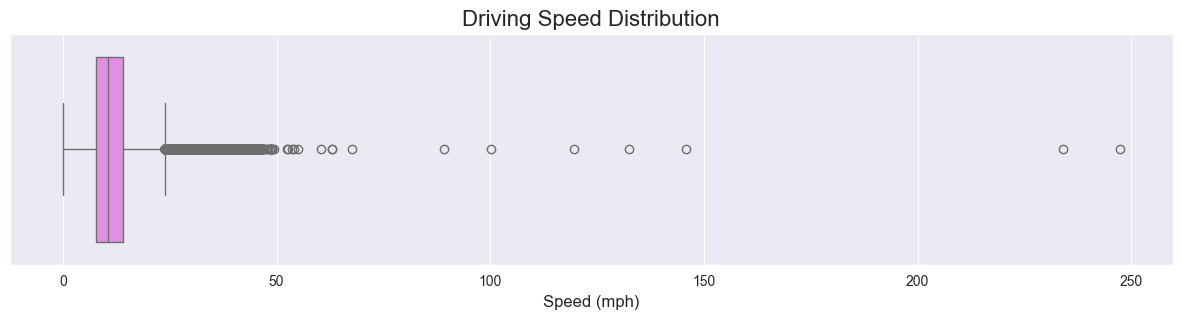

In [49]:
taxi['speed'] = (taxi['trip_distance'] / (taxi['length_time']/3600)).round(2)


plt.figure(figsize=(15, 3))
sns.set_style("darkgrid")
sns.boxplot(data = taxi, x = 'speed', color = 'violet')
plt.xlabel('Speed (mph)')
plt.title('Driving Speed Distribution', fontsize=16)
plt.show()

In [50]:
taxi.loc[taxi['speed'] > 55, 'length_time'] = np.nan
numerical_cols = taxi.select_dtypes(include=['int', 'float']).columns

knn_imputer = KNNImputer(n_neighbors=5)  
taxi[numerical_cols] = knn_imputer.fit_transform(taxi[numerical_cols])
taxi['speed'] = (taxi['trip_distance'] / (taxi['length_time']/3600)).round(2)

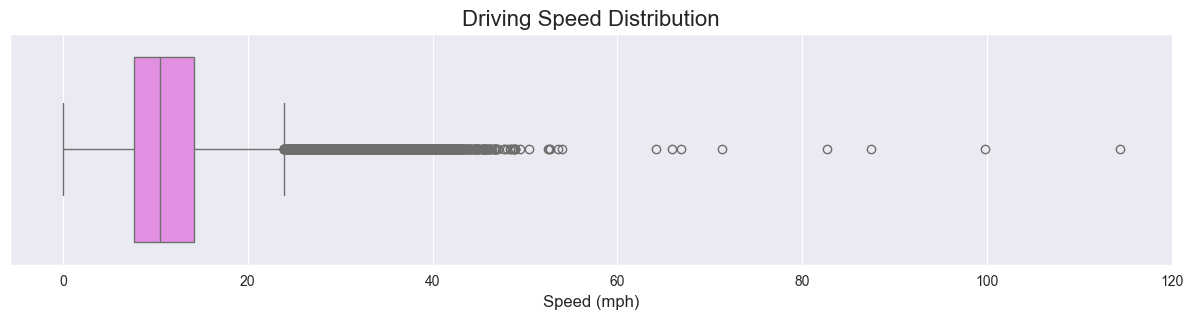

In [51]:
plt.figure(figsize=(15, 3))
sns.set_style("darkgrid")
sns.boxplot(data = taxi, x = 'speed', color = 'violet')
plt.xlabel('Speed (mph)')
plt.title('Driving Speed Distribution', fontsize=16)
plt.show()

In [52]:
from pandas.tseries.holiday import USFederalHolidayCalendar

def impute_fare_outliers(data):

    base_fare_threshold = 2.5
    #MTA_threshold = 0.5
    night_surcharge_threshold = 3.5 # 2.5 base fare, 0.5 dollar of night surcharge, 0.5 MTA tax
    rush_hour_threshold = 3.5         # 2.5 base fare, 1 dollar of rush hour surcharge, 0.5 MTA tax

    
    # Base fare checks
    base_fare_condition = (data['fare_amount'] <= base_fare_threshold)
    data.loc[base_fare_condition, 'fare_amount'] = base_fare_threshold

    # Night surcharge (8pm to 6am, inclusive of 20, 21, ... 6)
    night_surcharge_condition = ((data['pickup_hour'] >= 20) | (data['pickup_hour'] < 6)) & (data['fare_amount'] <= night_surcharge_threshold)
    data.loc[night_surcharge_condition, 'fare_amount'] = night_surcharge_threshold
    
    # Rush hour surcharge (4pm to 8pm on weekdays, excluding holidays) #here you need to check if there were holidays in May 2015
    calendar = USFederalHolidayCalendar()
    holiday_calendar = calendar.holidays(start='2015-05-01', end='2015-05-31')
    holidays = holiday_calendar.date

    # Update the rush hour condition to exclude holidays
    weekdays = [1, 2, 3, 4, 5]
    rush_hour_condition = ((data['pickup_hour'] >= 16) & (data['pickup_hour'] < 20) & 
                       (data['pickup_wday'].isin(weekdays)) &
                       (~data['pickup_date'].isin(holidays)) &
                       (data['fare_amount'] <= rush_hour_threshold))
    data.loc[rush_hour_condition, 'fare_amount'] = rush_hour_threshold  

    # High fare amount
    #high_fare = (data['fare_amount'] > 100) 
    #data.loc[high_fare, 'fare_amount'] = # do something


    return data

taxi = impute_fare_outliers(taxi)

In [53]:
taxi.head()


,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone,distance_bin,speed,time_of_day
0,2015-05-24,7.0,5.0,21.0,145.0,7.0,807.0,1.0,MN31,1.0,MN17,-73.951279,40.769939,-73.973137,40.759491,2.0,1.0,2.27,1.863849,0.406151,10.5,MN31-MN17,Manhattan,Manhattan,Lenox Hill East,Midtown Center,[2-3),10.13,Morning
1,2015-05-21,0.0,5.0,21.0,142.0,4.0,1458.0,1.0,MN23,3.0,BK73,-73.998993,40.730064,-73.959808,40.710918,1.0,1.0,3.20,3.369924,0.169924,18.0,MN23-BK73,Manhattan,Brooklyn,Greenwich Village South,Williamsburg (South Side),[3-5),7.90,Night
2,2015-05-04,23.0,5.0,18.0,125.0,1.0,495.0,1.0,MN27,3.0,BK76,-73.994148,40.717796,-73.948204,40.722595,1.0,1.0,3.40,2.733419,0.666581,12.0,MN27-BK76,Manhattan,Brooklyn,Lower East Side,Greenpoint,[3-5),24.73,Night
3,2015-05-13,19.0,5.0,20.0,134.0,3.0,941.0,1.0,MN20,1.0,MN40,-73.979813,40.743240,-73.952881,40.780380,2.0,2.0,2.93,3.970840,1.040840,13.0,MN20-MN40,Manhattan,Manhattan,Kips Bay,Upper East Side North,[2-3),11.21,Evening
4,2015-05-01,20.0,5.0,18.0,122.0,5.0,141.0,1.0,MN22,1.0,MN22,-73.983543,40.726109,-73.988991,40.729980,2.0,1.0,0.47,0.551991,0.081991,3.5,MN22-MN22,Manhattan,Manhattan,East Village,East Village,[0-1),12.00,Evening


In [54]:
float_cols = ['pickup_hour', 'pickup_month', 'pickup_week', 'pickup_doy', 'pickup_wday', 'length_time', 'pickup_BoroCode', 'dropoff_BoroCode', 'vendor_id', 'passenger_count']
taxi[float_cols] = taxi[float_cols].astype('int64')


In [55]:
taxi.head()

,pickup_date,pickup_hour,pickup_month,pickup_week,pickup_doy,pickup_wday,length_time,pickup_BoroCode,pickup_NTACode,dropoff_BoroCode,dropoff_NTACode,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,vendor_id,passenger_count,trip_distance,manhattan_distance,distance_diff,fare_amount,pair,pickup_Borough,dropoff_Borough,pickup_zone,dropoff_zone,distance_bin,speed,time_of_day
0,2015-05-24,7,5,21,145,7,807,1,MN31,1,MN17,-73.951279,40.769939,-73.973137,40.759491,2,1,2.27,1.863849,0.406151,10.5,MN31-MN17,Manhattan,Manhattan,Lenox Hill East,Midtown Center,[2-3),10.13,Morning
1,2015-05-21,0,5,21,142,4,1458,1,MN23,3,BK73,-73.998993,40.730064,-73.959808,40.710918,1,1,3.20,3.369924,0.169924,18.0,MN23-BK73,Manhattan,Brooklyn,Greenwich Village South,Williamsburg (South Side),[3-5),7.90,Night
2,2015-05-04,23,5,18,125,1,495,1,MN27,3,BK76,-73.994148,40.717796,-73.948204,40.722595,1,1,3.40,2.733419,0.666581,12.0,MN27-BK76,Manhattan,Brooklyn,Lower East Side,Greenpoint,[3-5),24.73,Night
3,2015-05-13,19,5,20,134,3,941,1,MN20,1,MN40,-73.979813,40.743240,-73.952881,40.780380,2,2,2.93,3.970840,1.040840,13.0,MN20-MN40,Manhattan,Manhattan,Kips Bay,Upper East Side North,[2-3),11.21,Evening
4,2015-05-01,20,5,18,122,5,141,1,MN22,1,MN22,-73.983543,40.726109,-73.988991,40.729980,2,1,0.47,0.551991,0.081991,3.5,MN22-MN22,Manhattan,Manhattan,East Village,East Village,[0-1),12.00,Evening


In [57]:
taxi.to_csv('/Users/Elizabeth/Desktop/Data Science/taxi_pred.csv')
